# Lab 7 : Support Vector Machine (SVM) Classification

## Aim
Implement a **Linear SVM** and kernel-based SVM classifiers, then compare the effect of different kernels on a benchmark dataset.

## Dataset
This lab uses the uploaded **Forest Fires** dataset (`forestfires.csv`). The original `area` column records the burned area and is numeric. Since this lab asks for classification, we convert it into a binary target:

- `0` = No area burned (`area == 0`)
- `1` = Some area burned (`area > 0`)

The original `area` column is removed from the input features so that the target does not leak into the model. This is a simple teaching classification task derived from the supplied dataset; it is not a claim that the dataset was originally collected as a classification benchmark.

## SVM kernels compared
- **Linear:** finds a linear separating boundary.
- **RBF:** can model curved, non-linear boundaries.
- **Polynomial:** models interactions with a polynomial boundary.
- **Sigmoid:** uses a sigmoid-shaped kernel function.

We use the same train/test split and preprocessing pipeline for all four models so that the comparison is fair.

## 1. Import libraries

In [16]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.svm import SVC
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    classification_report, ConfusionMatrixDisplay
)

pd.set_option("display.max_columns", None)


## 2. Load the dataset

In [17]:

df = pd.read_csv("forestfires.csv")

print("Dataset shape:", df.shape)
display(df.head())


Dataset shape: (517, 13)


,X,Y,month,day,FFMC,DMC,DC,ISI,temp,RH,wind,rain,area
0,7,5,mar,fri,86.2,26.2,94.3,5.1,8.2,51,6.7,0.0,0.0
1,7,4,oct,tue,90.6,35.4,669.1,6.7,18.0,33,0.9,0.0,0.0
2,7,4,oct,sat,90.6,43.7,686.9,6.7,14.6,33,1.3,0.0,0.0
3,8,6,mar,fri,91.7,33.3,77.5,9.0,8.3,97,4.0,0.2,0.0
4,8,6,mar,sun,89.3,51.3,102.2,9.6,11.4,99,1.8,0.0,0.0


## 3. Explore the data and create the classification target

In [18]:
print("Column information:")
df.info()

print("\nMissing values in each column:")
display(df.isnull().sum().to_frame("Missing values"))

df["burned"] = (df["area"] > 0).astype(int)

print("\nTarget distribution:")
display(df["burned"].value_counts().rename(index={0: "No area burned", 1: "Area burned"}).to_frame("Count"))
print("\nTarget proportions:")
display((df["burned"].value_counts(normalize=True) * 100).round(2).to_frame("Percentage"))


Column information:
<class 'pandas.DataFrame'>
RangeIndex: 517 entries, 0 to 516
Data columns (total 13 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   X       517 non-null    int64  
 1   Y       517 non-null    int64  
 2   month   517 non-null    str    
 3   day     517 non-null    str    
 4   FFMC    517 non-null    float64
 5   DMC     517 non-null    float64
 6   DC      517 non-null    float64
 7   ISI     517 non-null    float64
 8   temp    517 non-null    float64
 9   RH      517 non-null    int64  
 10  wind    517 non-null    float64
 11  rain    517 non-null    float64
 12  area    517 non-null    float64
dtypes: float64(8), int64(3), str(2)
memory usage: 52.6 KB

Missing values in each column:


,Missing values
X,0
Y,0
month,0
day,0
FFMC,0
DMC,0
DC,0
ISI,0
temp,0
RH,0



Target distribution:


,Count
burned,
Area burned,270
No area burned,247



Target proportions:


,Percentage
burned,
1,52.22
0,47.78


## 4. Prepare features and target

We remove `area` because it was used to create the target. We also separate the categorical columns (`month`, `day`) from numeric columns. Numeric features are standardized because SVM is sensitive to feature scales. Categorical features are converted into numeric columns using one-hot encoding.

In [19]:
# Target: 0 = no burned area, 1 = burned area
X = df.drop(columns=["area", "burned"])
y = df["burned"]

categorical_features = ["month", "day"]
numeric_features = [column for column in X.columns if column not in categorical_features]

preprocessor = ColumnTransformer(
    transformers=[
        ("numeric", StandardScaler(), numeric_features),
        ("categorical", OneHotEncoder(handle_unknown="ignore"), categorical_features)
    ]
)

print("Numeric features:", numeric_features)
print("Categorical features:", categorical_features)


Numeric features: ['X', 'Y', 'FFMC', 'DMC', 'DC', 'ISI', 'temp', 'RH', 'wind', 'rain']
Categorical features: ['month', 'day']


## 5. Split data into training and testing sets

In [20]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training rows:", X_train.shape[0])
print("Testing rows:", X_test.shape[0])
print("Training class proportions:")
display(y_train.value_counts(normalize=True).round(3).to_frame("Proportion"))


Training rows: 413
Testing rows: 104
Training class proportions:


,Proportion
burned,
1,0.523
0,0.477


## 6. Build and train SVM models

Each model uses the same preprocessing steps. `class_weight="balanced"` adjusts class weights based on the training data. We compare four kernel choices while keeping the main SVM setting (`C=1`) the same.

In [21]:
kernel_names = ["linear", "rbf", "poly", "sigmoid"]
models = {}

for kernel in kernel_names:
    models[kernel] = Pipeline(steps=[
        ("preprocessing", preprocessor),
        ("svm", SVC(kernel=kernel, C=1.0, gamma="scale", class_weight="balanced"))
    ])

for kernel, model in models.items():
    model.fit(X_train, y_train)
    print(f"Trained {kernel.upper()} SVM")


Trained LINEAR SVM
Trained RBF SVM
Trained POLY SVM
Trained SIGMOID SVM


## 7. Compare model performance on the test set

In [22]:
results = []
predictions = {}

for kernel, model in models.items():
    y_pred = model.predict(X_test)
    predictions[kernel] = y_pred
    results.append({
        "Kernel": kernel.upper(),
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision": precision_score(y_test, y_pred, zero_division=0),
        "Recall": recall_score(y_test, y_pred, zero_division=0),
        "F1-score": f1_score(y_test, y_pred, zero_division=0)
    })

results_df = pd.DataFrame(results).sort_values("F1-score", ascending=False).reset_index(drop=True)
display(results_df.round(3))


,Kernel,Accuracy,Precision,Recall,F1-score
0,POLY,0.587,0.568,0.852,0.681
1,RBF,0.606,0.600,0.722,0.655
2,LINEAR,0.558,0.569,0.611,0.589
3,SIGMOID,0.500,0.531,0.315,0.395


## 8. Compare kernels using 5-fold cross-validation

A single train/test split can be affected by which rows happen to be selected. Cross-validation repeats the evaluation over five different folds of the training data. We report mean accuracy and mean F1-score.

In [23]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
cv_results = []

for kernel, model in models.items():
    scores = cross_validate(
        model,
        X_train,
        y_train,
        cv=cv,
        scoring={"accuracy": "accuracy", "f1": "f1"},
        n_jobs=-1
    )
    cv_results.append({
        "Kernel": kernel.upper(),
        "Mean CV Accuracy": scores["test_accuracy"].mean(),
        "Mean CV F1-score": scores["test_f1"].mean()
    })

cv_df = pd.DataFrame(cv_results).sort_values("Mean CV F1-score", ascending=False).reset_index(drop=True)
display(cv_df.round(3))


,Kernel,Mean CV Accuracy,Mean CV F1-score
0,POLY,0.525,0.607
1,LINEAR,0.504,0.560
2,RBF,0.516,0.560
3,SIGMOID,0.496,0.526


## 9. Confusion matrix and classification report for the best test-set model

Best kernel based on test F1-score: POLY

Classification report:
                precision    recall  f1-score   support

No area burned       0.65      0.30      0.41        50
   Area burned       0.57      0.85      0.68        54

      accuracy                           0.59       104
     macro avg       0.61      0.58      0.55       104
  weighted avg       0.61      0.59      0.55       104



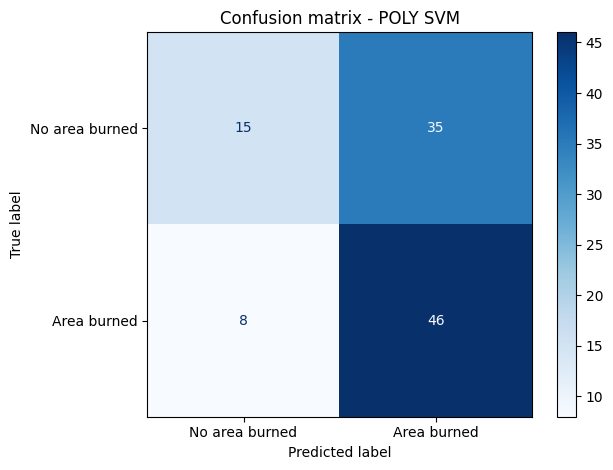

In [24]:
best_kernel = results_df.loc[0, "Kernel"].lower()
best_model = models[best_kernel]
best_predictions = predictions[best_kernel]

print("Best kernel based on test F1-score:", best_kernel.upper())
print("\nClassification report:")
print(classification_report(
    y_test,
    best_predictions,
    target_names=["No area burned", "Area burned"],
    zero_division=0
))

ConfusionMatrixDisplay.from_predictions(
    y_test,
    best_predictions,
    display_labels=["No area burned", "Area burned"],
    cmap="Blues",
    values_format="d"
)
plt.title(f"Confusion matrix - {best_kernel.upper()} SVM")
plt.tight_layout()
plt.show()
